In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("./datasets/smartcart_customers.csv")

In [7]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [8]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [9]:
#preprocessing of data

#handle missing val
df["Income"] = df["Income"].fillna(df["Income"].median())

In [10]:
#feature improvement

#convertig the year of birth to age 
df["Age"] = 2026 - df["Year_Birth"]

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_data = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_data - df["Dt_Customer"]).dt.days

In [11]:
# df.sample(5)
# df.columns

In [12]:
#spending(for customer segmentation only)

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
#Educaction

# df["Education"].value_counts()

# converting to undergrad , grad , postgrad

df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate",
})

# df["Marital_Status"].value_counts()

df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone","Divorced": "Alone","Widow": "Alone","Alone": "Alone","Absurd": "Alone", "YOLO": "Alone" 
})
# df["Living_With"].value_counts()

In [14]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spendingcols = ["MntWines", "MntFruits" , "MntMeatProducts" , "MntFishProducts" , "MntSweetProducts" , "MntGoldProds"]

In [15]:
cols_to_drop = cols + spendingcols

df_cleaned = df.drop(columns = cols_to_drop)

In [16]:
# df_cleaned

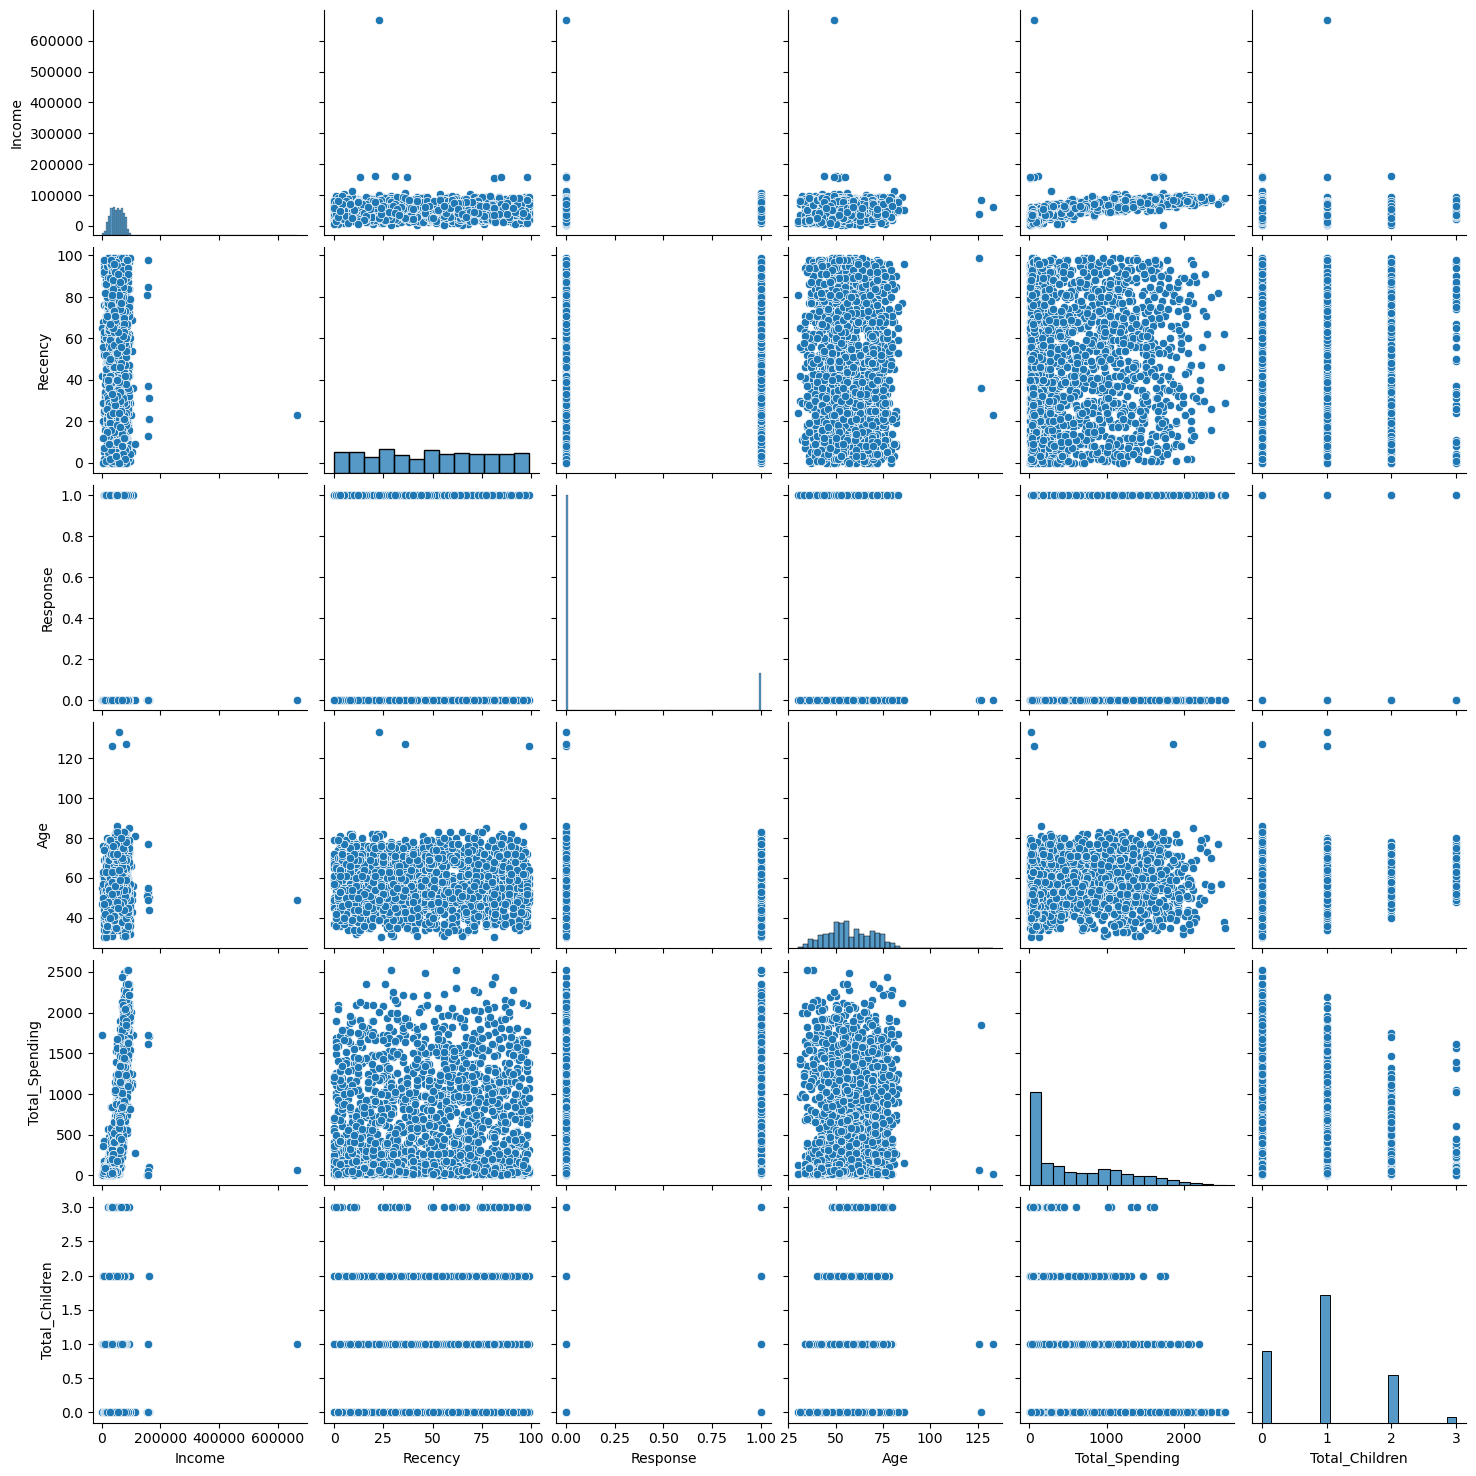

In [17]:
#Removing outlier

cols = ["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]

#relative plt

sns.pairplot(df_cleaned[cols])

In [18]:
#removal of income and age outlier

print("data_size_original", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print("data size after removal of outliers", len(df_cleaned))


data_size_original 2240
data size after removal of outliers 2236


<Axes: >

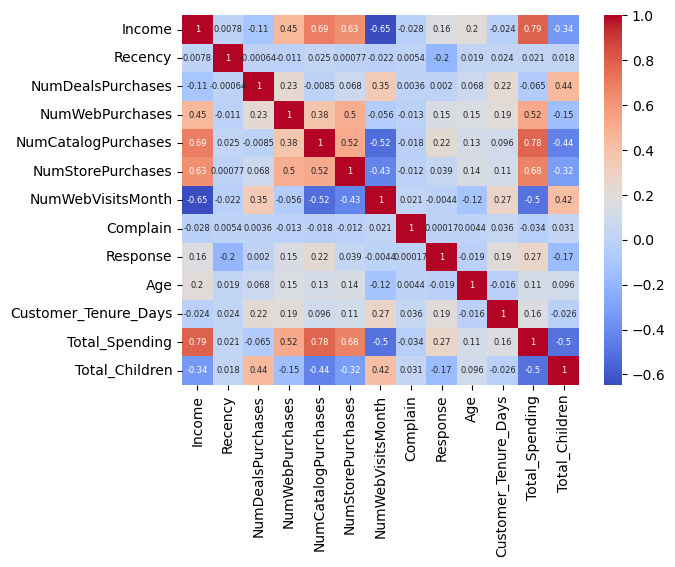

In [19]:
#checking corelation
corr = df_cleaned.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size": 6},
    cmap="coolwarm"
)

In [24]:
#encoding

from sklearn.preprocessing import OneHotEncoder

In [25]:
ohc = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

enc_cols = ohc.fit_transform(df_cleaned[cat_cols])

In [28]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns=ohc.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [29]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [31]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols), enc_df], axis=1)

In [32]:
df_encoded

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,1.0,0.0,0.0,0.0,1.0
2236,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,0.0,1.0,0.0,0.0,1.0
2237,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,1.0,0.0,0.0,1.0,0.0
2238,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,0.0,1.0,0.0,0.0,1.0


In [33]:
#scaling of the data 
from sklearn.preprocessing import StandardScaler

In [34]:
scaler = StandardScaler()

X = df_encoded

X_scaled = scaler.fit_transform(X)

In [36]:
X_scaled.shape

(2236, 18)

In [37]:
#visulaization

#2d 
from sklearn.decomposition import PCA

In [43]:
# pca = PCA(n_components = 2)
# X_pca = pca.fit_transform(X_scaled)

pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

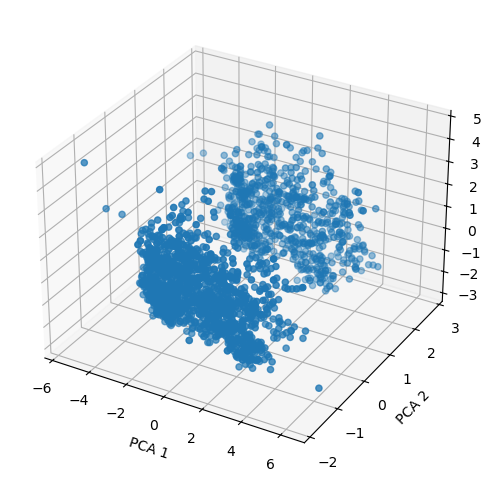

In [52]:
#plot

# plt.scatter(X_pca[:, 0], X_pca[:, 1])

fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    # s=20
)

ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

plt.show()

In [45]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

In [55]:
#applying knn
from sklearn.cluster import KMeans
from kneed import KneeLocator
#getiing best k val

#elbow method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)


In [58]:
knee = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")

optimal_k = knee.elbow

In [60]:
print("best k on elbow", optimal_k)

best k on elbow 4


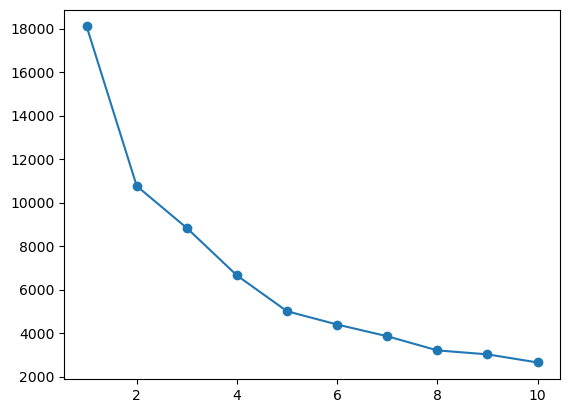

In [61]:
#plot

plt.plot(range(1, 11), wcss, marker="o")

In [68]:
#shilhoutte score

from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels =  kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

Text(0, 0.5, 'silhouette score')

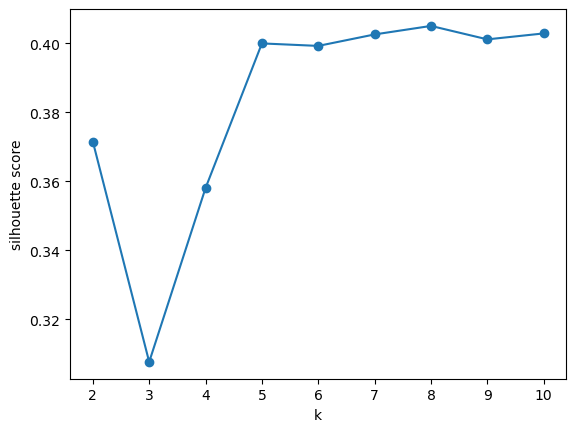

In [70]:
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("k")
plt.ylabel("silhouette score")

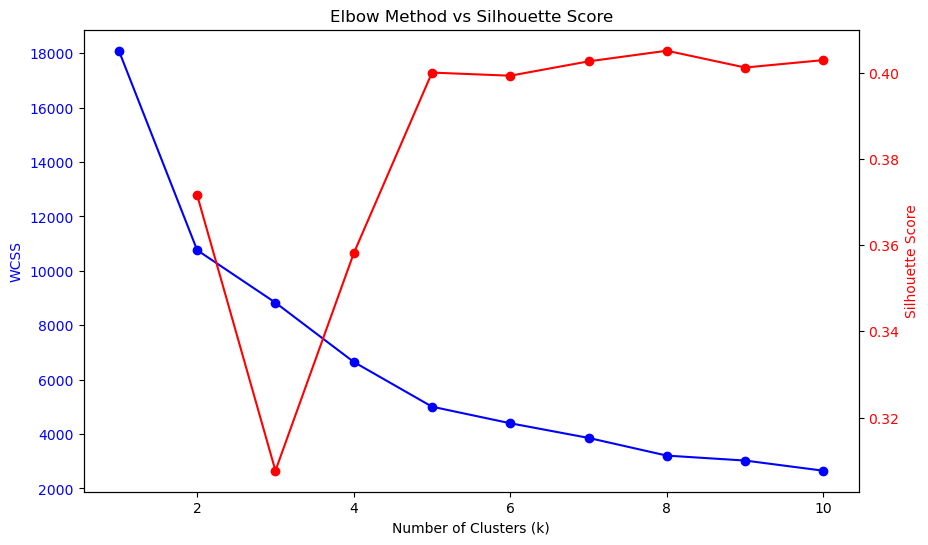

In [71]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(range(1, 11), wcss, marker="o", color="blue", label="WCSS")

ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("WCSS", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Silhouette score plot (second Y-axis)
ax2 = ax1.twinx()

ax2.plot(range(2, 11), scores, marker="o", color="red", label="Silhouette Score")

ax2.set_ylabel("Silhouette Score", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Elbow Method vs Silhouette Score")
plt.show()

In [72]:
#clustering with k means

kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(X_pca)

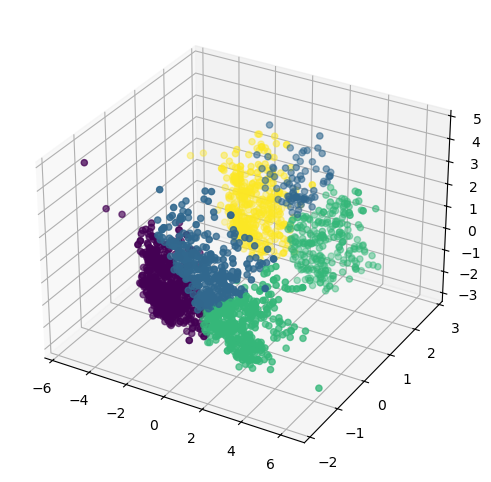

In [77]:
#plot

fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=labels
)

plt.show()

In [78]:
#alglomorative
from sklearn.cluster import AgglomerativeClustering

In [83]:
agg_clstr = AgglomerativeClustering(n_clusters = 4, linkage="ward")
labels_agg = agg_clstr.fit_predict(X_pca)

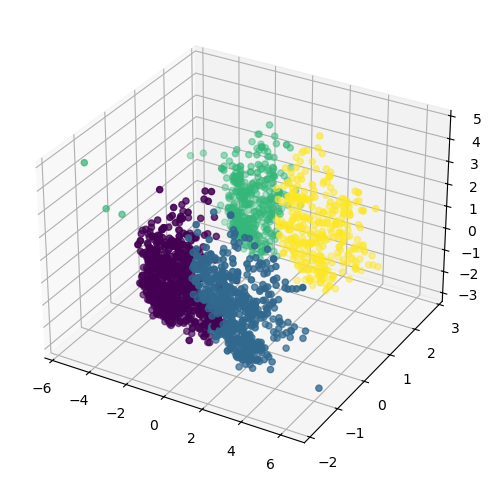

In [84]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=labels_agg
)

plt.show()

In [104]:
#charecterization
# df_cleaned["cluster"] = labels_agg
X["cluster"] = labels_agg

In [105]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

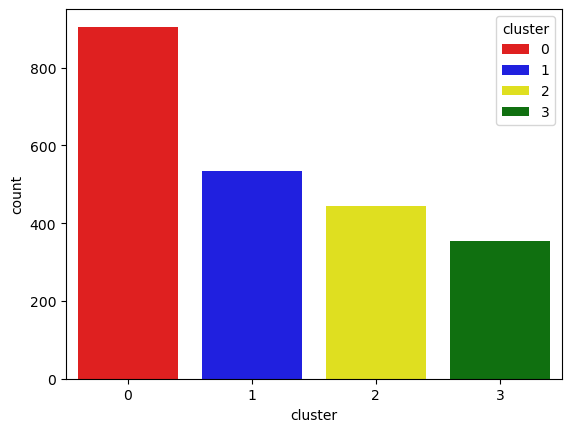

In [106]:
plat = ["red", "blue", "yellow", "green"]

sns.countplot(x=X["cluster"], palette=plat, hue=X["cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

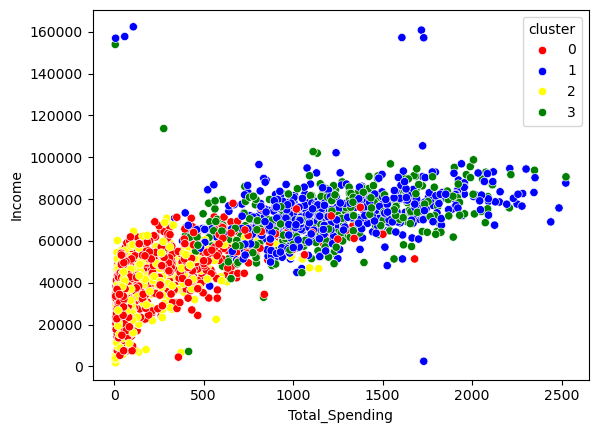

In [107]:
sns.scatterplot(x=X["Total_Spending"], y=X["Income"], hue=X["cluster"], palette=plat)

In [109]:
# summary 


cluster_summary = X.groupby("cluster").mean()

In [110]:
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
cluster         

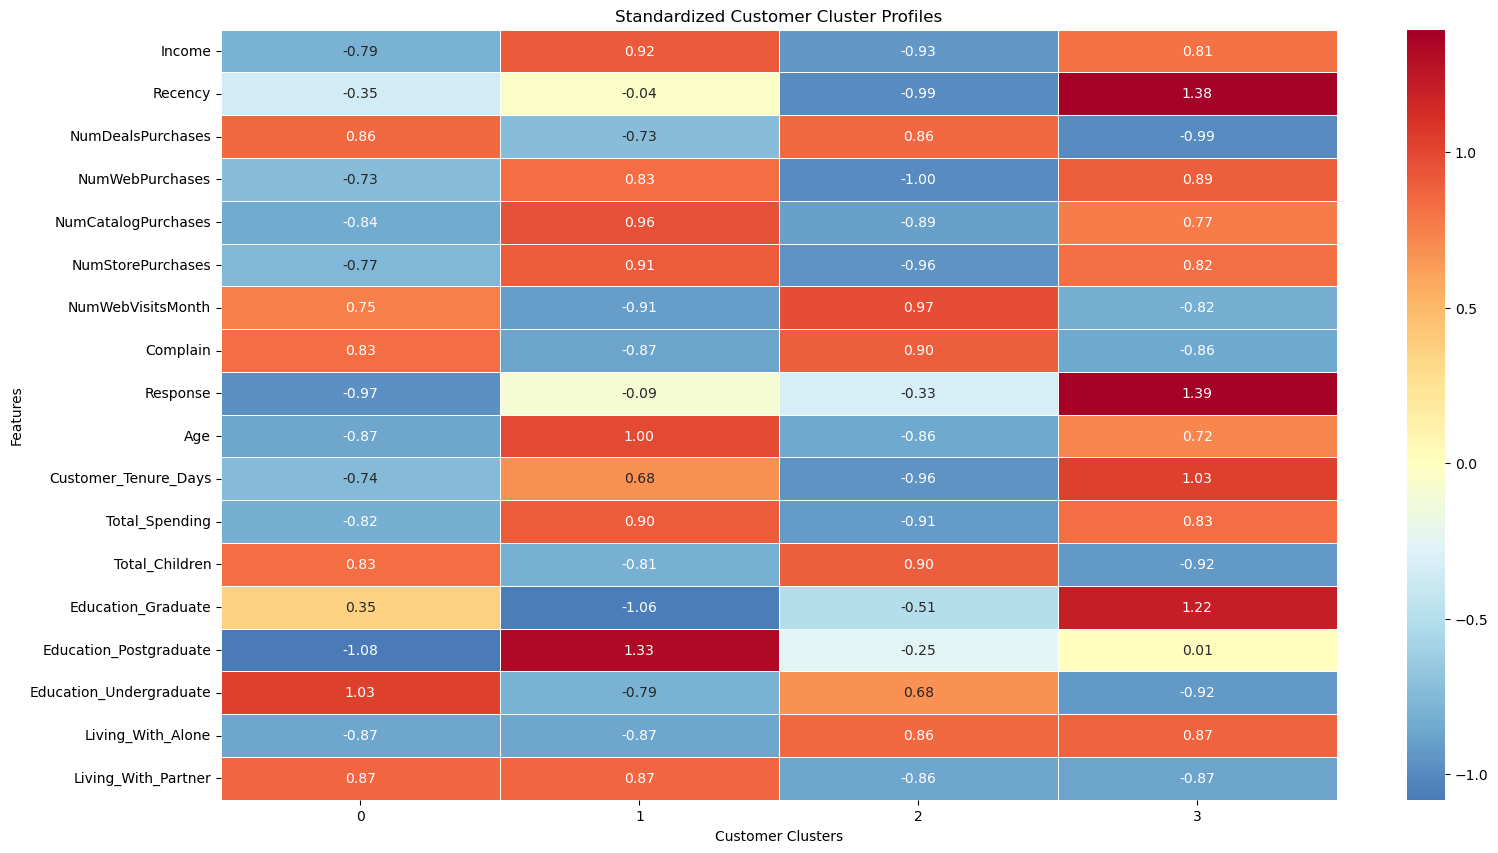

In [112]:
cluster_scaled = cluster_summary.apply(
    lambda x: (x - x.mean()) / x.std(),
    axis=0
)

plt.figure(figsize=(18, 10))

sns.heatmap(
    cluster_scaled.T,
    annot=True,
    cmap="RdYlBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Standardized Customer Cluster Profiles")
plt.xlabel("Customer Clusters")
plt.ylabel("Features")
plt.show()


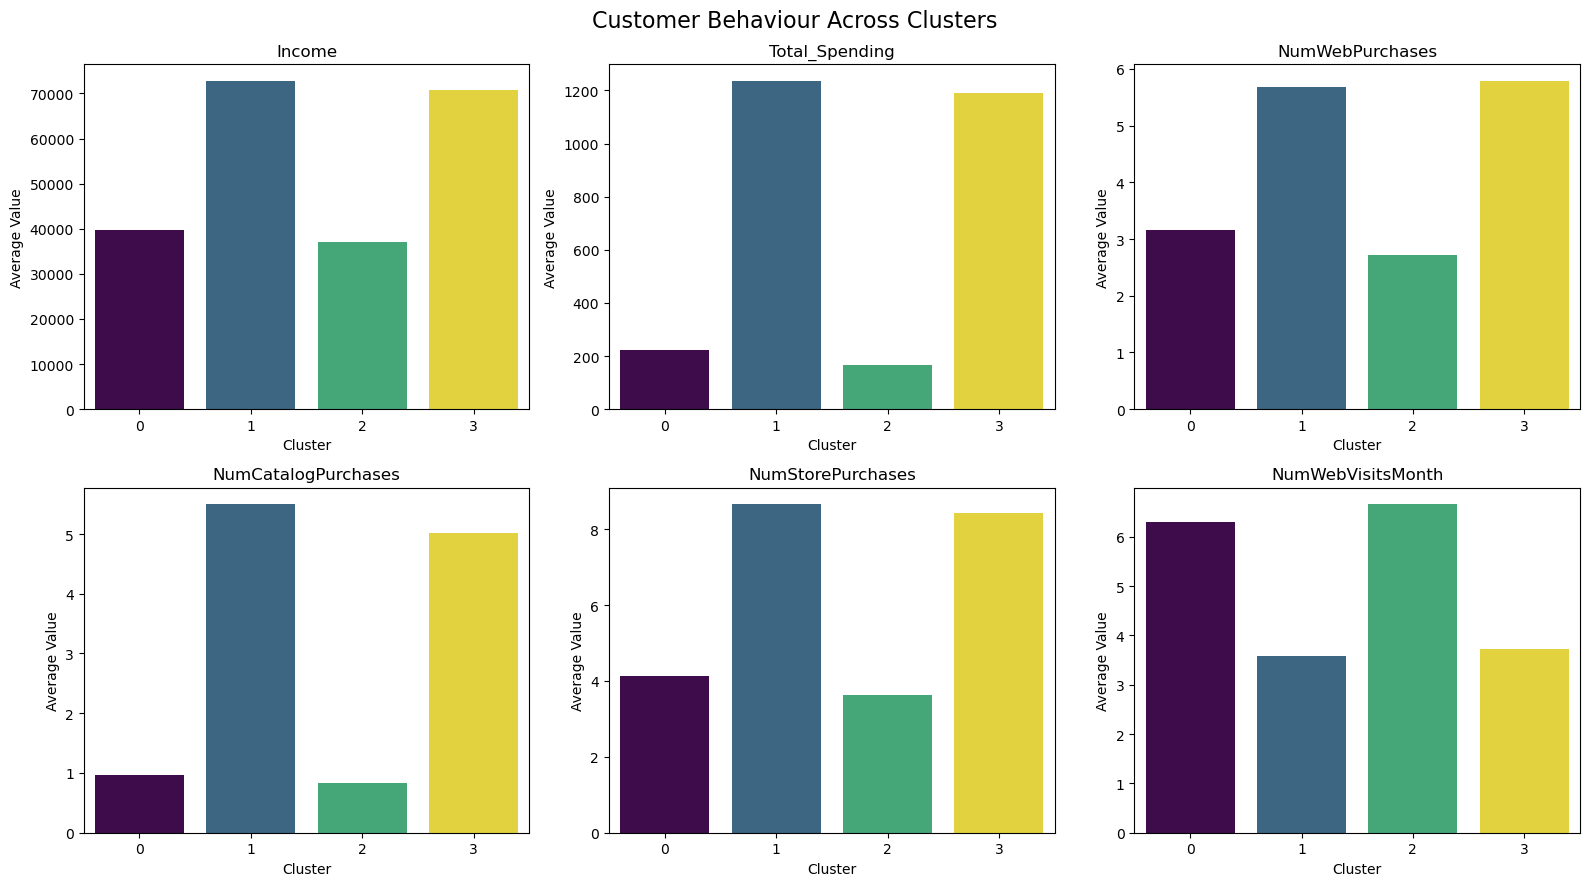

In [113]:
features = [
    "Income",
    "Total_Spending",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(features, axes.flatten()):
    sns.barplot(
        x=cluster_summary.index,
        y=cluster_summary[feature],
        ax=ax,
        hue=cluster_summary.index,
        palette="viridis",
        legend=False
    )

    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Average Value")

plt.suptitle("Customer Behaviour Across Clusters", fontsize=16)
plt.tight_layout()
plt.show()